<h1><font color="orange"><b>Prediction of academic success using logistic regression</b></font></h1>

In [35]:
import pandas as pd

In [7]:
data = pd.read_csv("student_performance_dataset.csv")

In [8]:
data

,Student_ID,Gender,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Parental_Education_Level,Internet_Access_at_Home,Extracurricular_Activities,Final_Exam_Score,Pass_Fail
0,S147,Male,31,68.267841,86,High School,Yes,Yes,63,Pass
1,S136,Male,16,78.222927,73,PhD,No,No,50,Fail
2,S209,Female,21,87.525096,74,PhD,Yes,No,55,Fail
3,S458,Female,27,92.076483,99,Bachelors,No,No,65,Pass
4,S078,Female,37,98.655517,63,Masters,No,Yes,70,Pass
...,...,...,...,...,...,...,...,...,...,...
703,S492,Male,14,84.658761,78,PhD,Yes,No,50,Fail
704,S301,Male,35,60.278990,83,Masters,No,No,62,Pass
705,S473,Male,25,98.384969,75,Bachelors,Yes,No,57,Fail
706,S307,Female,21,96.148012,84,Bachelors,Yes,No,65,Pass


In [9]:
df = data.dropna()

In [10]:
df

,Student_ID,Gender,Study_Hours_per_Week,Attendance_Rate,Past_Exam_Scores,Parental_Education_Level,Internet_Access_at_Home,Extracurricular_Activities,Final_Exam_Score,Pass_Fail
0,S147,Male,31,68.267841,86,High School,Yes,Yes,63,Pass
1,S136,Male,16,78.222927,73,PhD,No,No,50,Fail
2,S209,Female,21,87.525096,74,PhD,Yes,No,55,Fail
3,S458,Female,27,92.076483,99,Bachelors,No,No,65,Pass
4,S078,Female,37,98.655517,63,Masters,No,Yes,70,Pass
...,...,...,...,...,...,...,...,...,...,...
703,S492,Male,14,84.658761,78,PhD,Yes,No,50,Fail
704,S301,Male,35,60.278990,83,Masters,No,No,62,Pass
705,S473,Male,25,98.384969,75,Bachelors,Yes,No,57,Fail
706,S307,Female,21,96.148012,84,Bachelors,Yes,No,65,Pass


In [11]:
target_col = 'Pass_Fail'
exp_cols = ['Study_Hours_per_Week', 'Attendance_Rate', 'Past_Exam_Scores']

In [12]:
X = data[exp_cols]
y = data[target_col]

In [13]:
from sklearn.model_selection import train_test_split

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.33, stratify=y)

In [24]:
from sklearn.preprocessing import StandardScaler

In [25]:
scaler =StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [15]:
from sklearn.linear_model import LogisticRegression

In [26]:
model = LogisticRegression()
trained_model = model.fit(X_train_scaled, y_train)

In [27]:
y_pred = model.predict(X_test_scaled)

In [19]:
from sklearn.metrics import classification_report

In [28]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        Fail       0.78      0.77      0.77       117
        Pass       0.77      0.78      0.77       117

    accuracy                           0.77       234
   macro avg       0.77      0.77      0.77       234
weighted avg       0.77      0.77      0.77       234



In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [29]:
cm = confusion_matrix(y_test, y_pred, normalize='true')

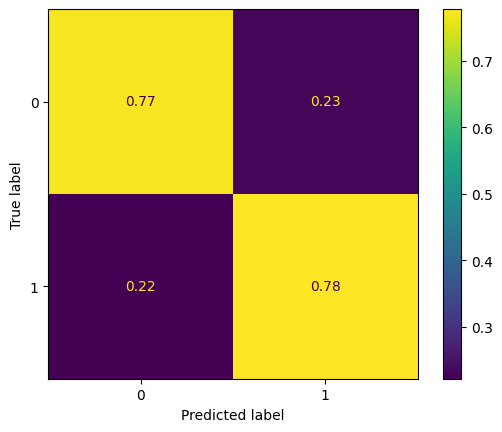

In [30]:
disp = ConfusionMatrixDisplay(confusion_matrix = cm)
disp.plot()
plt.show()

In [32]:
model.coef_

array([[1.08601713, 1.62324889, 1.70860029]])

In [33]:
model.intercept_

array([-0.10736677])

In [34]:
model.classes_

array(['Fail', 'Pass'], dtype=object)

In [31]:
model.score(X_test_scaled,y_test)

0.7735042735042735